# Online Retail Analysis (Python, Pandas)

In [227]:
# Import libraries for data analysis and visualisation
import pandas as pd
import matplotlib.pyplot as plt

In [228]:
# Load the Online Retail II dataset
retail = pd.read_csv(r"C:\projects\archive (7)\online_retail_II.csv")
retail.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


## Cleaning

In [229]:
# Convert InvoiceDate from text into datetime so dates can be grouped for analysis
retail['InvoiceDate'] = pd.to_datetime(retail['InvoiceDate'])
retail.dtypes

Invoice                object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[ns]
Price                 float64
Customer ID           float64
Country                object
dtype: object

In [230]:
# Identify any cancelled orders by checking if the invoice number starts with a 'C'
retail['Cancelled Status'] = retail['Invoice'].str.startswith('C')
# Save cancelled orders separately before removing them from the main dataset
Cancellations = retail.loc[retail['Cancelled Status'] == True]
# Count the amount of cancelled orders
retail['Cancelled Status'].value_counts()

Cancelled Status
False    1047877
True       19494
Name: count, dtype: int64

In [231]:
# Keep only rows where Quantity and Price are greater than 0 as negative values are returns
retail = retail.loc[(retail['Quantity'] > 0) & (retail['Price'] > 0)]

In [232]:
# Count the amount of duplicate rows
retail.duplicated().sum()

np.int64(33757)

In [233]:
# Remove duplicates so sales aren't counted twice
retail = retail.loc[retail.duplicated() == False]
# Check no duplicates remain
retail.duplicated().sum()

np.int64(0)

In [234]:
# Standardise stock codes into upper case
retail['StockCode'] = retail['StockCode'].str.upper()
# Standardise descriptions into title case and remove extra spaces
retail['Description'] = retail['Description'].str.strip().str.title()
retail.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,Cancelled Status
0,489434,85048,15Cm Christmas Glass Ball 20 Lights,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom,False
1,489434,79323P,Pink Cherry Lights,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,False
2,489434,79323W,White Cherry Lights,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,False
3,489434,22041,"Record Frame 7"" Single Size",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom,False
4,489434,21232,Strawberry Ceramic Trinket Box,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom,False


In [235]:
# Check for missing product names
retail['Description'].isna().sum()

np.int64(0)

In [236]:
# Check for missing customer IDs
retail['Customer ID'].isna().sum()

np.int64(228489)

In [237]:
# Create a Revenue column
retail['Revenue'] = retail['Price'] * retail['Quantity']
retail

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,Cancelled Status,Revenue
0,489434,85048,15Cm Christmas Glass Ball 20 Lights,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom,False,83.40
1,489434,79323P,Pink Cherry Lights,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,False,81.00
2,489434,79323W,White Cherry Lights,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,False,81.00
3,489434,22041,"Record Frame 7"" Single Size",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom,False,100.80
4,489434,21232,Strawberry Ceramic Trinket Box,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom,False,30.00
...,...,...,...,...,...,...,...,...,...,...
1067366,581587,22899,Children'S Apron Dolly Girl,6,2011-12-09 12:50:00,2.10,12680.0,France,False,12.60
1067367,581587,23254,Childrens Cutlery Dolly Girl,4,2011-12-09 12:50:00,4.15,12680.0,France,False,16.60
1067368,581587,23255,Childrens Cutlery Circus Parade,4,2011-12-09 12:50:00,4.15,12680.0,France,False,16.60
1067369,581587,22138,Baking Set 9 Piece Retrospot,3,2011-12-09 12:50:00,4.95,12680.0,France,False,14.85


In [238]:
# Calculate amount of rows removed during cleaning
Rows_removed_retail = 1067371 - len(retail)
Rows_removed_retail

59457

In [239]:
# Calculate the percentage of rows removed during cleaning
Rows_removed_retail_percentage = (1067371 - len(retail)) / 1067371 * 100
Rows_removed_retail_percentage

5.57041553499205

## Sales trends

In [240]:
# Extract the year and month from InvoiceDate to create columns for analysis
retail['InvoiceYear'] = retail['InvoiceDate'].dt.year
retail['InvoiceMonth'] = retail['InvoiceDate'].dt.month
retail.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,Cancelled Status,Revenue,InvoiceYear,InvoiceMonth
0,489434,85048,15Cm Christmas Glass Ball 20 Lights,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom,False,83.4,2009,12
1,489434,79323P,Pink Cherry Lights,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,False,81.0,2009,12
2,489434,79323W,White Cherry Lights,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,False,81.0,2009,12
3,489434,22041,"Record Frame 7"" Single Size",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom,False,100.8,2009,12
4,489434,21232,Strawberry Ceramic Trinket Box,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom,False,30.0,2009,12


In [241]:
# Calculate total revenue by month and its corresponding year
Monthly_revenue = retail.groupby(['InvoiceYear', 'InvoiceMonth'])['Revenue'].sum()
Monthly_revenue

InvoiceYear  InvoiceMonth
2009         12               822483.950
2010         1                651155.112
             2                551878.296
             3                830915.261
             4                678875.252
             5                657705.500
             6                749537.310
             7                648810.270
             8                695251.910
             9                921696.991
             10              1161902.220
             11              1464293.142
             12               821452.730
2011         1                689811.610
             2                522545.560
             3                716215.260
             4                536968.491
             5                769296.610
             6                760547.010
             7                718076.121
             8                757841.380
             9               1056435.192
             10              1151263.730
             11              15

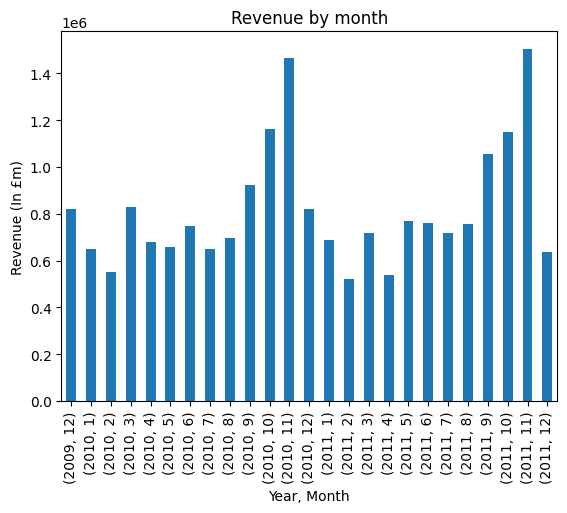

In [242]:
# Create a bar chart to visualise monthly revenue
Monthly_revenue.plot(kind = 'bar')
plt.title('Revenue by month')
plt.xlabel('Year, Month')
plt.ylabel('Revenue (In £m)')
plt.show()

In [243]:
# Month-on-month revenue growth by percentage
Monthly_growth = round(Monthly_revenue.pct_change() * 100, 1)
Monthly_growth

InvoiceYear  InvoiceMonth
2009         12               NaN
2010         1              -20.8
             2              -15.2
             3               50.6
             4              -18.3
             5               -3.1
             6               14.0
             7              -13.4
             8                7.2
             9               32.6
             10              26.1
             11              26.0
             12             -43.9
2011         1              -16.0
             2              -24.2
             3               37.1
             4              -25.0
             5               43.3
             6               -1.1
             7               -5.6
             8                5.5
             9               39.4
             10               9.0
             11              30.6
             12             -57.6
Name: Revenue, dtype: float64

In [244]:
# 3 month rolling average of revenue
rolling_average = round(Monthly_revenue.rolling(3).mean(), 0)
rolling_average

InvoiceYear  InvoiceMonth
2009         12                    NaN
2010         1                     NaN
             2                675172.0
             3                677983.0
             4                687223.0
             5                722499.0
             6                695373.0
             7                685351.0
             8                697866.0
             9                755253.0
             10               926284.0
             11              1182631.0
             12              1149216.0
2011         1                991852.0
             2                677937.0
             3                642857.0
             4                591910.0
             5                674160.0
             6                688937.0
             7                749307.0
             8                745488.0
             9                844118.0
             10               988513.0
             11              1237189.0
             12              1097646.0

In [245]:
# Extract day of the week and hour to identify the busiest times
retail['InvoiceDay'] = retail['InvoiceDate'].dt.day_name()
retail['InvoiceHour'] = retail['InvoiceDate'].dt.hour
retail.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,Cancelled Status,Revenue,InvoiceYear,InvoiceMonth,InvoiceDay,InvoiceHour
0,489434,85048,15Cm Christmas Glass Ball 20 Lights,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom,False,83.4,2009,12,Tuesday,7
1,489434,79323P,Pink Cherry Lights,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,False,81.0,2009,12,Tuesday,7
2,489434,79323W,White Cherry Lights,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,False,81.0,2009,12,Tuesday,7
3,489434,22041,"Record Frame 7"" Single Size",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom,False,100.8,2009,12,Tuesday,7
4,489434,21232,Strawberry Ceramic Trinket Box,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom,False,30.0,2009,12,Tuesday,7


In [246]:
# Total revenue by day of the week
Day_revenue = retail.groupby('InvoiceDay')['Revenue'].sum()
Day_revenue

InvoiceDay
Friday       3323908.883
Monday       3581967.746
Saturday        9803.050
Sunday       1799147.282
Thursday     4195212.762
Tuesday      4078149.962
Wednesday    3488444.333
Name: Revenue, dtype: float64

In [247]:
# Create a pivot table to show total revenue by day of the week and hour
Revenue_by_day_and_hour = retail.pivot_table(index='InvoiceDay', columns='InvoiceHour', values='Revenue', aggfunc='sum')
Revenue_by_day_and_hour

InvoiceHour,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20
InvoiceDay,,,,,,,,,,,,,,,
Friday,NaN,22194.72,108720.71,474362.691,449327.690,419160.760,446595.600,368091.412,408247.700,330528.980,168344.210,111427.550,16514.63,373.04,19.19
Monday,NaN,15880.42,91141.21,316820.900,421929.331,392753.922,438270.870,484227.080,386550.610,352989.671,412970.861,245169.111,23263.76,NaN,NaN
Saturday,NaN,NaN,NaN,NaN,1059.740,230.200,2110.650,2520.490,1130.930,1599.740,1151.300,NaN,NaN,NaN,NaN
Sunday,NaN,NaN,NaN,2853.120,173514.150,321886.500,346781.891,349088.170,244088.091,280023.010,80541.320,371.030,NaN,NaN,NaN
Thursday,4.25,16027.41,122036.54,329639.320,506021.701,426175.280,546577.150,407140.011,463131.700,500289.430,337345.860,226093.490,180682.78,108856.14,25191.70
Tuesday,NaN,11532.26,117734.72,350764.900,545229.681,543516.710,506113.820,493426.900,405480.790,554421.910,328486.280,154373.471,51698.95,14707.77,661.80
Wednesday,NaN,10130.76,88925.96,295190.100,484049.040,431602.091,563927.690,443973.481,413054.910,375091.051,241303.970,124025.480,1244.90,2893.40,13031.50


## Products

In [248]:
# Top 10 products by revenue (first look contains non-product descriptions like 'postage') 
Top_products_by_revenue = retail.groupby('Description')['Revenue'].sum().sort_values(ascending = False)
Top_products_by_revenue.head(10)

Description
Manual                                339614.86
Regency Cakestand 3 Tier              330590.32
Dotcom Postage                        309854.11
White Hanging Heart T-Light Holder    260990.22
Paper Craft , Little Birdie           168469.60
Party Bunting                         148318.28
Jumbo Bag Red Retrospot               148073.47
Assorted Colour Bird Ornament         129324.49
Postage                               125682.42
Paper Chain Kit 50'S Christmas        117760.29
Name: Revenue, dtype: float64

In [249]:
# Remove non-products from the data (second look still contains 'postage')
products = retail.loc[(retail['Description'] != 'Manual') & (retail['Description'] != 'Dotcom Postage')]
# Top 10 products by revenue after removing non-products
Top_products_by_revenue_updated = products.groupby('Description')['Revenue'].sum().sort_values(ascending = False)
Top_products_by_revenue_updated.head(10)

Description
Regency Cakestand 3 Tier              330590.32
White Hanging Heart T-Light Holder    260990.22
Paper Craft , Little Birdie           168469.60
Party Bunting                         148318.28
Jumbo Bag Red Retrospot               148073.47
Assorted Colour Bird Ornament         129324.49
Postage                               125682.42
Paper Chain Kit 50'S Christmas        117760.29
Medium Ceramic Top Storage Jar         81700.92
Chilli Lights                          80540.88
Name: Revenue, dtype: float64

In [250]:
# Top 10 products by revenue after removing all non-products
products_updated = retail.loc[(retail['Description'] != 'Manual') & (retail['Description'] != 'Dotcom Postage') & (retail['Description'] != 'Postage')]
Top_products_by_revenue_clean = products_updated.groupby('Description')['Revenue'].sum().sort_values(ascending = False)
Top_products_by_revenue_clean.head(10)

Description
Regency Cakestand 3 Tier               330590.32
White Hanging Heart T-Light Holder     260990.22
Paper Craft , Little Birdie            168469.60
Party Bunting                          148318.28
Jumbo Bag Red Retrospot                148073.47
Assorted Colour Bird Ornament          129324.49
Paper Chain Kit 50'S Christmas         117760.29
Medium Ceramic Top Storage Jar          81700.92
Chilli Lights                           80540.88
Rotating Silver Angels T-Light Hldr     71300.40
Name: Revenue, dtype: float64

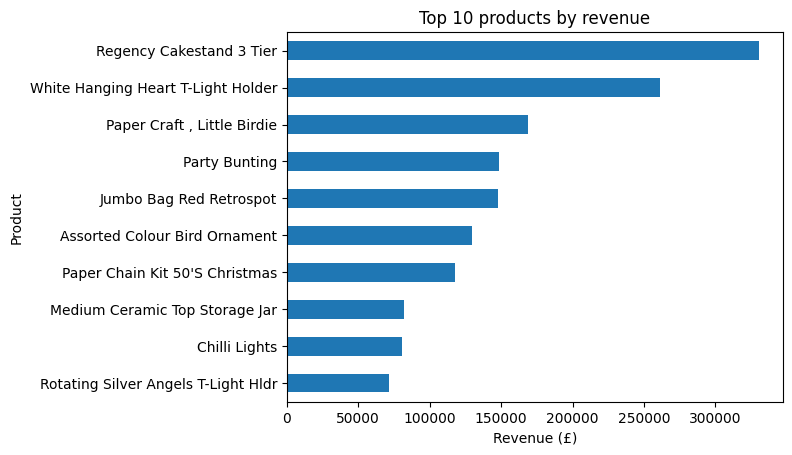

In [251]:
# Horizontal bar chart of the top 10 products
Top_products_by_revenue_clean.head(10).sort_values().plot(kind = 'barh')
plt.title('Top 10 products by revenue')
plt.xlabel('Revenue (£)')
plt.ylabel('Product')
plt.show()

## Countries

In [252]:
# Total revenue by each country, highest to lowest
Country_revenue = round(retail.groupby('Country')['Revenue'].sum().sort_values(ascending = False),1)
Country_revenue.head(10)

Country
United Kingdom    17410569.7
EIRE                658767.3
Netherlands         554038.1
Germany             425019.7
France              350456.1
Australia           169283.5
Spain               108332.5
Switzerland         100685.6
Sweden               91869.8
Denmark              68580.7
Name: Revenue, dtype: float64

In [253]:
# Rename 'EIRE' to 'Ireland' for name consistency
retail.loc[retail['Country'] == 'EIRE', 'Country'] = 'Ireland'

In [254]:
# Top 10 countries by revenue after renaming 'EIRE' to 'Ireland'
Country_revenue_updated = round(retail.groupby('Country')['Revenue'].sum().sort_values(ascending = False),1)
Country_revenue_updated.head(10)

Country
United Kingdom    17410569.7
Ireland             658767.3
Netherlands         554038.1
Germany             425019.7
France              350456.1
Australia           169283.5
Spain               108332.5
Switzerland         100685.6
Sweden               91869.8
Denmark              68580.7
Name: Revenue, dtype: float64

In [255]:
# Top 10 countries by percentage of total revenue
Country_share = round(Country_revenue_updated / Country_revenue_updated.sum() * 100, 1)
Country_share.head(10)

Country
United Kingdom    85.0
Ireland            3.2
Netherlands        2.7
Germany            2.1
France             1.7
Australia          0.8
Spain              0.5
Switzerland        0.5
Sweden             0.4
Denmark            0.3
Name: Revenue, dtype: float64

## Customer segments

In [256]:
# Create a dataframe with only the rows that have a customer ID
Retail_with_all_IDs =  retail.loc[retail['Customer ID'].isna() == False]

# Total spent and number of orders by each customer
Customer_summary = Retail_with_all_IDs.groupby('Customer ID').agg(
                                                                  Total_spent=('Revenue', 'sum'),
                                                                  Orders=('Invoice', 'nunique'))
Customer_summary.head()

,Total_spent,Orders
Customer ID,,
12346.0,77556.46,12
12347.0,4921.53,8
12348.0,2019.40,5
12349.0,4428.69,4
12350.0,334.40,1


In [257]:
# Look at the distribution of total spent by customers
Customer_summary['Total_spent'].describe()

count      5878.000000
mean       2955.904095
std       14440.852688
min           2.950000
25%         342.280000
50%         867.740000
75%        2248.305000
max      580987.040000
Name: Total_spent, dtype: float64

In [258]:
# Segment customers by total amount spent into Low (<£1000), Mid (£1000-£5000), and High (>£5000)
Customer_summary['Segment'] = 'Low'
Customer_summary.loc[Customer_summary['Total_spent'] > 1000, 'Segment'] = 'Mid'
Customer_summary.loc[Customer_summary['Total_spent'] > 5000, 'Segment'] = 'High'
#Number of customers in each segment
Customer_summary['Segment'].value_counts()

Segment
Low     3173
Mid     2060
High     645
Name: count, dtype: int64

In [259]:
# Total revenue by segment
Segment_revenue = round(Customer_summary.groupby('Segment')['Total_spent'].sum(), 1)
Segment_revenue

Segment
High    11405400.1
Low      1334802.5
Mid      4634601.7
Name: Total_spent, dtype: float64

In [260]:
# Total share of revenue by segment
Segment_share = round( Segment_revenue / Segment_revenue.sum() * 100,1)
Segment_share

Segment
High    65.6
Low      7.7
Mid     26.7
Name: Total_spent, dtype: float64

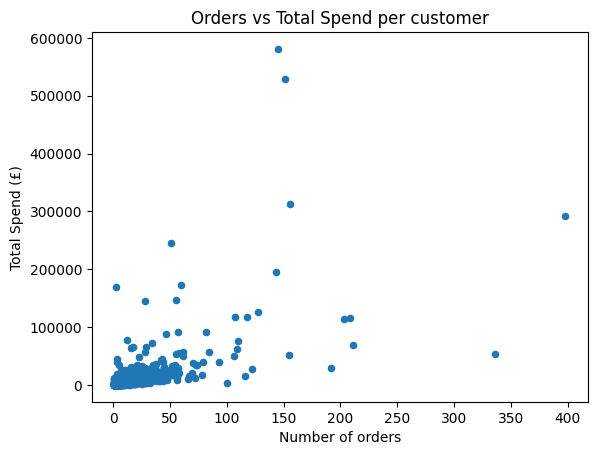

In [261]:
# Create a scatter plot to visualise the relationship with the amount of orders and total amount spent
Customer_summary.plot(kind = 'scatter', x='Orders', y='Total_spent')
plt.title('Orders vs Total Spend per customer')
plt.xlabel('Number of orders')
plt.ylabel('Total Spend (£)')
plt.show()

In [262]:
# Each segment's share of customers
Customer_share = round(Customer_summary['Segment'].value_counts() / len(Customer_summary) * 100, 1)
Customer_share

Segment
Low     54.0
Mid     35.0
High    11.0
Name: count, dtype: float64

In [263]:
# Compare share and revenue sorted by most valuable segment
Segment_table = pd.DataFrame({'% of revenue': Segment_share, '% of customers' : Customer_share}).sort_values('% of revenue', ascending = False)
Segment_table

,% of revenue,% of customers
Segment,,
High,65.6,11.0
Mid,26.7,35.0
Low,7.7,54.0
